In [1]:
import xarray as xr
import Namelist as gv
import numpy as np

import os

from tools.util import int2str, fix_coords

In [2]:

def get_cov_fname(iy):
	'''
	Simple function to keep covariance matrix naming the same 
	across two other functions
	'''
	return gv.pre_path + 'Cov_' + int2str(iy, 4) + '.nc'


## could add a pass through tools.util.py/fix_coords
def preprocess(ds):
	'''
	preprocess for xarray open_mfdataset to handle messy ERA5 data
    may not always be needed
	'''
	# ## drop 'number' coord if present 
	# if 'number' in ds.coords:
	# 	ds = ds.drop_vars('number')

	# ## order level and dtype across all files
	# ds = ds.sortby('level')
	# ds['level'] = ds['level'].astype('int32')

	## drop 'number' if present
	if 'number' in ds.coords:
		ds = ds.drop_vars('number')

	## subset to just the levels needed
	ds = ds.sel(level=[250, 850])     
	ds['level'] = ds['level'].astype('int32')

	return ds


monthly_csv = gv.monthlycsv
with open(monthly_csv,'r') as f:
    df_mary = f.readlines()

df_sub_uam = []
df_sub_vam = []
df_sub_hurm = []
df_sub_uad = []
df_sub_vad = []
                                                                    
for ia in df_mary:
    #print(ia)
    if 'u_component' in ia and 'daily' not in ia:
        df_sub_uam.append(ia[:-1])
    if 'u_component' in ia and 'dailymean' in ia:
        df_sub_uad.append(ia[:-1])
    if 'v_component' in ia and 'daily' not in ia:
        df_sub_vam.append(ia[:-1])
    if 'v_component' in ia and 'dailymean' in ia:
        df_sub_vad.append(ia[:-1])
    if 'relative_humidity' in ia:
        df_sub_hurm.append(ia[:-1])
df_sub_uam = np.array(df_sub_uam)
df_sub_vam = np.array(df_sub_vam)
df_sub_hurm = np.array(df_sub_hurm)
df_sub_uad = np.array(df_sub_uad)
df_sub_vad = np.array(df_sub_vad)

## splits string, depends on correct naming 
modely1m = np.int_([df_sub_uam[i].split('/')[-1].split('_')[-1][:4] for i in range(df_sub_uam.shape[0])])
modely2m = np.int_([df_sub_uam[i].split('/')[-1].split('_')[-1].split('-')[-1][:4] for i in range(df_sub_uam.shape[0])])

##### reading daily data through Lamont URL
##### daily_csv should be in the namelist.py
modely1d = np.int_([df_sub_vad[i].split('/')[-1].split('_')[-2][:4] for i in range(df_sub_vad.shape[0])])
modely2d = np.int_([df_sub_vad[i].split('/')[-1].split('_')[-2][:4] for i in range(df_sub_vad.shape[0])])

arg_y1 = -1
neighbors=((0,1),(0,-1),(1,0),(-1,0),(1,1),(-1,1),(1,-1),(-1,-1),(0,2),(0,-2),(2,0),(-2,0))

for iy in range(gv.Year1, gv.Year2+1):
    ## ovewrite protection:
    ## if Covariance Matrix export for a given year already exists
    ## and ovewrite = False in Namelist.py, then skip to the next year 
    cov_fname = get_cov_fname(iy)
    if os.path.exists(cov_fname) and not gv.overwrite:
        print(f'{cov_fname} exists, skipping {iy}')
        ## then continue on to next year in the for loop
        continue

    ## If the file doesn't exist or 
    ## overwrite is set to True

    arg_yd = np.argwhere((modely1d<=iy)&(modely2d>=iy)).ravel()
    arg_ym = np.argwhere((modely1m<=iy)&(modely2m>=iy)).ravel()[0]  

In [3]:


import time
files = df_sub_uad[arg_yd]   # arg_yd is defined before the open block, so this works

def test(label, **kw):
    t = time.perf_counter()
    ds = xr.open_mfdataset(files, **kw)
    t_open = time.perf_counter() - t
    arr = ds.u.data
    print(f'{label}: open={t_open:.2f}s dims={ds.u.dims} '
          f'chunks={arr.chunksize} tasks={len(arr.__dask_graph__())}')
    t = time.perf_counter()
    ds.u.sel(level=250).isel(day=slice(0, 31)).values   # ~one month at 250 hPa
    print(f'   first read: {time.perf_counter()-t:.1f}s')

test('A baseline')
test('B nested', combine='nested', concat_dim='day')
test('C preprocess', preprocess=preprocess)
test('D both', preprocess=preprocess, combine='nested', concat_dim='day')
test('A again')   # file-cache check

A baseline: open=0.30s dims=('day', 'level', 'latitude', 'longitude') chunks=(31, 2, 721, 1440) tasks=2
   first read: 0.2s
B nested: open=0.10s dims=('day', 'level', 'latitude', 'longitude') chunks=(31, 2, 721, 1440) tasks=36
   first read: 0.1s
C preprocess: open=0.10s dims=('day', 'level', 'latitude', 'longitude') chunks=(31, 2, 721, 1440) tasks=3
   first read: 0.1s
D both: open=0.11s dims=('day', 'level', 'latitude', 'longitude') chunks=(31, 2, 721, 1440) tasks=48
   first read: 0.1s
A again: open=0.09s dims=('day', 'level', 'latitude', 'longitude') chunks=(31, 2, 721, 1440) tasks=2
   first read: 0.1s


In [1]:
import xarray as xr
import numpy as np
import Namelist as gv
import pandas as pd

In [2]:
gv.dailycsv

'/home/miriamn/CHAZ/CHAZvectorized/list.txt'

In [3]:
xr.open_dataset("/xpt/berimbau.local/data2/clee/ERA5/era5data/v_component_of_wind_202512_dailymean.nc")

<xarray.Dataset> Size: 258MB
Dimensions:    (day: 31, level: 2, latitude: 721, longitude: 1440)
Coordinates:
  * day        (day) int64 248B 1 2 3 4 5 6 7 8 9 ... 23 24 25 26 27 28 29 30 31
    number     (day) float64 248B ...
  * level      (level) float64 16B 850.0 250.0
  * latitude   (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
Data variables:
    v          (day, level, latitude, longitude) float32 257MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-07-06T16:18 GRIB to CDM+CF via cfgrib-0.9.1...

In [4]:
ds = xr.open_dataset("/data0/miriamn/CHAZvectorized/pre/Cov_1950.nc").load()

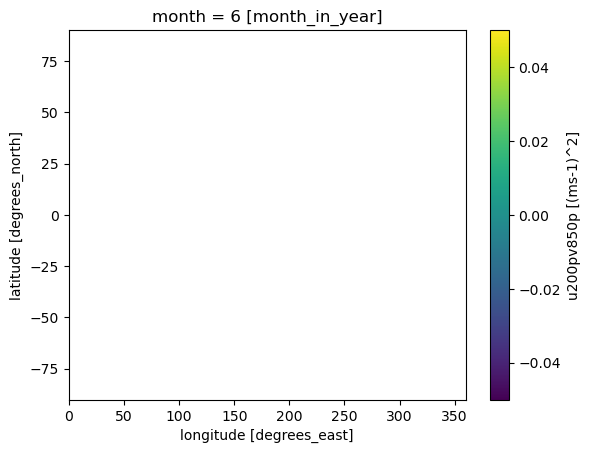

In [5]:
ds.sel(month = 6).u200pv850p.plot()

In [6]:
ds = xr.open_dataset("/data0/miriamn/CHAZvectorized/pre/A_195001.nc").load()

In [7]:
ds

<xarray.Dataset> Size: 20MB
Dimensions:    (Adim: 10, days: 31, latitude: 90, longitude: 180)
Coordinates:
  * Adim       (Adim) int32 40B 0 1 2 3 4 5 6 7 8 9
  * days       (days) int32 124B 0 1 2 3 4 5 6 7 8 ... 23 24 25 26 27 28 29 30
  * latitude   (latitude) float32 360B -89.0 -87.0 -85.0 ... 85.0 87.0 89.0
  * longitude  (longitude) float32 720B 0.0 2.0 4.0 6.0 ... 354.0 356.0 358.0
Data variables:
    A          (Adim, days, latitude, longitude) float32 20MB 6.399 ... 4.072

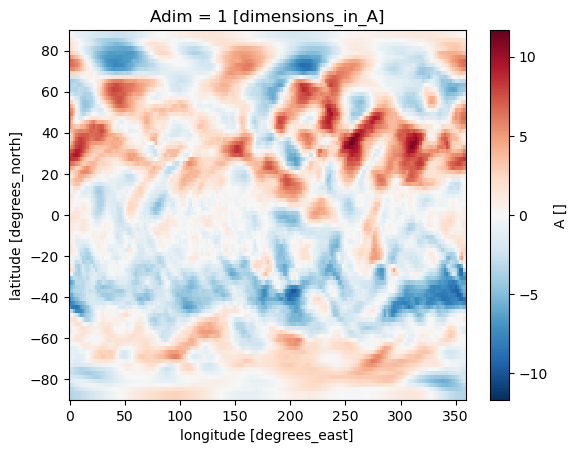

In [8]:
ds.A.mean(dim = 'days').sel(Adim = 1).plot()